This reads in a large commensurate structure from (commensurate.ionpos, commensurate.lattice, commensurate.aux)

It then constructs a sparse hamiltonian based on neighborhood hoppings (interpolating )

It then solves the hamiltonian for a specified set of kpoints

Finally, it plots the momentum resolved density of states n(q,E)



Some new features I would like to add:
Option to weight the qDOS based on the contribution from one layer or another. Plot 
Adding gaussian random noise to the Hamiltonian to see how robust it is to uncorrelated perturbations. 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

# Import common helper functions
from SPEARMINT_Utils import *

t_start = time.time()

Loading files...
['C1' 'C2' 'C3' 'C4']
[['C1', 'C2'], ['C3', 'C4']]
Creating Orbital Objects...
nOrbitals = 1672
Finding Orbital Neighbors...
Calculating Interlayer Registries...


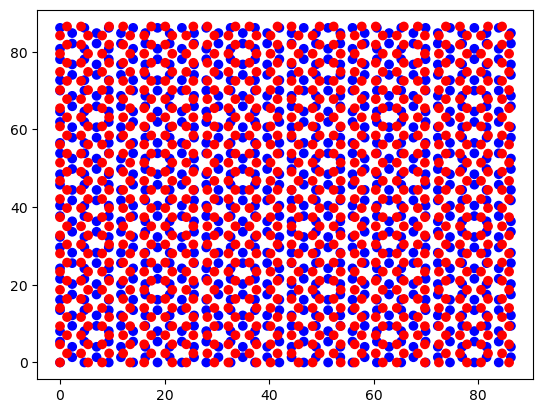

DONE!


In [2]:
# Form commensurate approximant system on which to compute a periodic Hamiltonian

##################################################################
global_path = "../data/30DEG_TBG/"
commensurate_sc_pat = global_path+"30TBG"
subs_uc_pat  = global_path+"graphene"
flake_uc_pat = global_path+"graphene"
neighborhoodRadius = 10 # bohr: Chosen to allow up to 5NN in graphene flake
##################################################################

# Flake rotation is hardcoded for this demonstration,
#   but could easily be read from files
DEGREES = np.pi/180
theta = 30*DEGREES
Flake_Rotation = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                           [np.sin(theta),  np.cos(theta), 0.0],
                           [0.0          ,  0.0          , 1.0]])

###### LOAD IN FILES ######
print("Loading files...")

# Load in strcutre files
ionpos, ionsp = get_ionpos_ionsp(commensurate_sc_pat+".ionpos")
M = get_LatticeMatrix(commensurate_sc_pat+".lattice")
# Load in ionpos labels differentiated by site symmetry information ionsp.aux
symIonsps, ucIndxs, isFlakes = readIonspAux(commensurate_sc_pat+".aux")
unique_symIonsp = np.unique(symIonsps)
print(unique_symIonsp)
# Make an array to find symIonsp labels based of isFlake and ucIndx
unique_symIonsp_Arr = [['',''],['','']] #(np.max(ucIndxs)+1)*[ ['',''] ] 
for symIonsp, ucIndx, isFlake in zip(symIonsps, ucIndxs, isFlakes):
    unique_symIonsp_Arr[isFlake][ucIndx] = symIonsp
print(unique_symIonsp_Arr)

# Load the substrate unitcell
subs_uc_ionpos, flake_uc_ionsp = get_ionpos_ionsp(subs_uc_pat+".ionpos")
subs_uc_lattice = get_LatticeMatrix(subs_uc_pat+".lattice")
# Load the flake unitcell
flake_uc_ionpos, flake_uc_ionsp = get_ionpos_ionsp(flake_uc_pat+".ionpos")
flake_uc_lattice = get_LatticeMatrix(flake_uc_pat+".lattice")
# Rotate the flake unitcell
flake_uc_lattice = np.dot(Flake_Rotation, flake_uc_lattice)


##### CREATE ORBITAL OBJECTS #####

# NOTE: For this demonstration on 30-TBG the code assumes a 1:1 map between 
#   wannier orbitals and atomic centers (from .ionpos files)

print("Creating Orbital Objects...")
# Create an orbital object for each orbital site 
wannierCenters = np.copy(ionpos)    
nOrbitals = wannierCenters.shape[0]
print("nOrbitals =", nOrbitals)

# For each orbital i, create an Orbital object to organize information about this orbital
#    set its centers_indx, ionpos_indx, and isFlake
orbitals = []
for i in range(nOrbitals):
    ionpos_indx = i 
    # Find the index of the ion in the flake/subs material unitcell that corresponds to this orbital
    #   using the information from ionsp.aux
    # Do the same for whether the orbital is in the flake or the substrate
    # Exclude orbitals with negative ionpos labels (indicating they are from terminating atoms)
    if ucIndxs[ionpos_indx] >= 0:
        orb = Orbital(i, ionpos_indx, ucIndxs[ionpos_indx], isFlakes[ionpos_indx])
        orb.neighborhoodR = neighborhoodRadius
        orbitals.append( orb )

        
##### FIND ORBITAL NEIGHBORS #####
# Could be accelerated with numpy array calls, but it's fast enough anyway
print("Finding Orbital Neighbors...")
for orb_i in orbitals:
    # get location in cartesian coords
    ri = lat2cart(M, ionpos[orb_i.ionpos_indx])
    # find all of the other orbitals who are within the defined cylinder arround this orbital (PBC accounting!)
    for orb_j in orbitals:
        rj = lat2cart(M, ionpos[orb_j.ionpos_indx])
        # add orb_j to orb_i's list of neighbors if within the cylinder
        if mindistPBC(rj,ri,M,onlyXY=True) <= orb_i.neighborhoodR:
            (orb_i.neighbors).append(orb_j)
    
##### CALCULATE INTERLAYER REGISTRIES #####
print("Calculating Interlayer Registries...")
# Now calculate the interlayer registry for each orbital based on atomic center locations
for orb,i in zip(orbitals, range(len(orbitals))):
    orb.calcRegistry(ionpos,M,flake_uc_ionpos,flake_uc_lattice,subs_uc_ionpos,subs_uc_lattice)
        
# Plot the upperlayer in red and the lower layer in blue
c = []
for i in range(len(isFlakes)):
    if isFlakes[i]:
        c.append('r')
    else:
        c.append('b')

plt.scatter(lat2cart(M,ionpos)[:,0], lat2cart(M,ionpos)[:,1],c=c)
plt.show()
    
    
print("DONE!")

In [3]:
# Form the Hamiltonian

##### LOAD IN ORBITAL NEIGHBOR HOPPINGS DATA FILES #####

# load in header file that specifies which data to use 


class WannierDataSet:
    def __init__(self, ion1_id, orb1_id, registry1, dr, ion2_id, orb2_id, registry2, t):
        self.ion1_id   = ion1_id
        self.orb1_id   = orb1_id 
        self.registry1 = registry1 
        self.dr        = dr
        self.ion2_id   = ion2_id
        self.orb2_id   = orb2_id 
        self.registry2 = registry2 
        self.t         = t
    
    # Return a subset (e.g. hoppings from C1 to C4 orbitals)
    def selSubset(self, sel):
        self.ion1_id   = self.ion1_id  [sel]
        self.orb1_id   = self.orb1_id  [sel]
        self.registry1 = self.registry1[sel]
        self.dr        = self.dr       [sel]
        self.ion2_id   = self.ion2_id  [sel]
        self.orb2_id   = self.orb2_id  [sel]
        self.registry2 = self.registry2[sel]
        self.t         = self.t        [sel]
        
    # Makes a deep copy of the WannierDataSet
    def copy(self):
        return WannierDataSet(np.copy(self.ion1_id), np.copy(self.orb1_id), np.copy(self.registry1), np.copy(self.dr), np.copy(self.ion2_id), np.copy(self.orb2_id), np.copy(self.registry2), np.copy(self.t))
        

def read_wannierNNFile(filename):
    with open(filename) as f:
        lines = f.readlines()[1:] # skip first line
        lines = [ line.split() for line in lines ]
    return lines
        
def constructFlakeSizeDataSet(flakeSize_path,shift_paths, global_path):
    # Construct the dataset from each of my shift calculations:
    Data = []
    for shift_path in shift_paths:
        wannierNNfile = global_path + shift_path + flakeSize_path + "/wannier.NNhoppings"
        Data = Data + read_wannierNNFile(wannierNNfile)

    # Transpose this DataSet to access each field more easily 
    Data = list(zip(*Data))

    # Convert text fields into floats
    ion1_id   = np.array(Data[0])
    orb1_id   = np.array(Data[1])
    registry1 = np.array( [[float(x) for x in Data[2]], 
                           [float(x) for x in Data[3]]] ).T
    dr        = np.array( [[float(x) for x in Data[4]],
                           [float(x) for x in Data[5]],
                           [float(x) for x in Data[6]]] ).T
    ion2_id   = np.array(Data[7])
    orb2_id   = np.array(Data[8])
    registry2 = np.array( [[float(x) for x in Data[ 9]], 
                           [float(x) for x in Data[10]]] ).T
    t= np.array([float(x) for x in Data[11]])
    
    DataSet = WannierDataSet(ion1_id, orb1_id, registry1, dr, ion2_id, orb2_id, registry2,t)
    
    return DataSet

# Select only hoppings from orbital A to B from a given flakeSize dataset, optionally remove outliers
def getHoppingSubset(DataSet, A, B, removeOutliers=False):
    # Find a subset of the data where orbital type A hops to orbital type B
    selA = np.where(DataSet.ion1_id == A)
    selB = np.where(DataSet.ion2_id == B)
    selAandB = np.intersect1d(selA,selB)
    print("Orbital type A =", A)
    print("Orbital type B =", B)

    # Select training data only for when orbital type A hops to Orbital type B
    DataSet.selSubset(selAandB)

    # Optionally remove outliers where wannierzation may have been unstable
    #    Was not an issue for this demonstration
    if removeOutliers:
        print("Removing Outliers:")
        # Identify outliers (outside 2std ) in the output
        n_sigma = 3.0
        t = DataSet.t
        t_mean = np.average(t)
        t_std = np.std(t)
        selNotOutlier = np.intersect1d( np.where(t - (t_mean-n_sigma*t_std) > 0), np.where(t - (t_mean+n_sigma*t_std) < 0) )

        # Remove outliers from the data
        DataSet.selSubset(selNotOutlier)
    
    return DataSet

#######################################################################################
shift_paths = ["shift_00000_00000/" ,"shift_00000_16666/","shift_00000_33333/","shift_00000_50000/","shift_00000_66666/","shift_00000_83333/",
                "shift_16666_00000/","shift_16666_16666/","shift_16666_33333/","shift_16666_50000/","shift_16666_66666/","shift_16666_83333/",
                "shift_33333_00000/","shift_33333_16666/","shift_33333_33333/","shift_33333_50000/","shift_33333_66666/","shift_33333_83333/",
                "shift_50000_00000/","shift_50000_16666/","shift_50000_33333/","shift_50000_50000/","shift_50000_66666/","shift_50000_83333/",
                "shift_66666_00000/","shift_66666_16666/","shift_66666_33333/","shift_66666_50000/","shift_66666_66666/","shift_66666_83333/",
                "shift_83333_00000/","shift_83333_16666/","shift_83333_33333/","shift_83333_50000/","shift_83333_66666/","shift_83333_83333/"]

flakeSize_paths = ["C13H09", "C22H12", "C37H15"]
invFlakeSizes = 1.0/np.array([13,22,37])

#flakeSize_path = flakeSize_paths[2] # Choose the largest flake size for now
#######################################################################################

#DataSet = constructFlakeSizeDataSet(flakeSize_path,shift_paths, global_path) 

DataSetsByFlakeSize = []
for flakeSize_path in flakeSize_paths:
    DataSet = constructFlakeSizeDataSet(flakeSize_path,shift_paths, global_path)
    print("Read Large Dataset from Files")
    DataSetsByFlakeSize.append(DataSet)


def gaussian_kernel(r, sigma):
    return (1./(np.sqrt(2*np.pi)*sigma) ) * np.exp(-r**2/(2*sigma**2))

#  Adapted from the 1D implementation from:
#  https://www.kapilsharma.dev/posts/local-linear-regression/
def predict(xTest, xTr, yTr, h):
    if len(xTr) != len(yTr):
        raise ValueError("X and Y Should have same length")
    
    B = np.append( np.ones(xTr.shape[0])[:,None], xTr, axis=1 )
    
    y_hat = []
    for x0 in xTest:
        r = np.linalg.norm(xTr-x0, axis=-1)
        w = gaussian_kernel(r, h)
        W = np.diag(w)
        
        thingy = np.concatenate((np.ones(1), x0)).T
        y_hat.append(thingy.dot(
            np.linalg.inv(B.T.dot(W).dot(B))).dot(
            B.T).dot(W).dot(yTr))
    return np.array(y_hat)

def LLR(xPred, A, B, DataSet, h=0.3):
    print("xPred", xPred)
    # Select only A->B hoppings for fitting
    
    DataSet0 = getHoppingSubset(DataSet.copy(), A, B, removeOutliers=True)
    # Set up LLR prediction training data
    dr_x = DataSet0.dr[:,0]
    dr_y = DataSet0.dr[:,1]
    t    = DataSet0.t
    xTr = np.array([dr_x,dr_y]).T 
    yTr = t
    
#     # DEBUG: Plot the hopping t v.s. dx and dy
#     plt.title("dr_x,y scatter of t")
#     plt.scatter(dr_x, dr_y, c=t)
#     plt.colorbar()
#     plt.show()
    
    # Return the LLR prediction at xPred
    return predict([xPred], xTr, yTr, h) 
    
    
# My idea is that interpolation and extrapolation can be performed in one step
#    by adding an addional axis to the xTr/xTest to represent the inverse flake size.
#    weighting is done on the cartesian dimensions using a gaussian_kernel as before,
#    but the invFlakeSize dimension will all be weighted equally.
# To evaluate the interpolated values extrapolated to infinite size, 
#    the invFlakeSize dimenions of xTest should be zero.
def interpolateAndExtrapolate(xTest, xTr, yTr, h):
    if len(xTr) != len(yTr):
        raise ValueError("X and Y Should have same length")
    B = np.append( np.ones(xTr.shape[0])[:,None], xTr, axis=1 )
    # Separate the training and testing data into invFlakeSize and cartesian parts
    xTr_size   = xTr[:,0]
    xTr_cart   = xTr[:,1:]
    print(xTest.shape)
    xTest_size = xTest[:,0]
    xTest_cart = xTest[:,1:]
    # 
    y_hat = []
    for i, xi in enumerate(xTest):
        # weight datapoints based soley on their cartesian distance to the test point, regardless of invFlakeSize
        # This ensures that a linear fit is performed over the invFlakeSize dimension
        r = np.linalg.norm(xTr_cart-xTest_cart[i], axis=-1)
        w = gaussian_kernel(r, h)
        W = np.diag(w)
        #
        thingy = np.concatenate((np.ones(1), xi)).T
        y_hat.append(thingy.dot(
            np.linalg.inv(B.T.dot(W).dot(B))).dot(
            B.T).dot(W).dot(yTr))
    return np.array(y_hat)
    
    
def LLR_interp_extrap(xPred, A, B, DataSetsByFlakeSize, invFlakeSizes, h=0.3):
    print("xPred", xPred)
    
    # Form training dataset from all flake sizes now
    xTr = np.array([]).reshape(0,3)
    yTr = np.array([])
    for DataSet, invFlakeSize in zip(DataSetsByFlakeSize, invFlakeSizes):
        # Get sublattice hopping subset
        DataSet0 = getHoppingSubset(DataSet.copy(), A, B, removeOutliers=False) # no outliers removed
        
        dr_x = DataSet0.dr[:,0]
        dr_y = DataSet0.dr[:,1]
        t    = DataSet0.t
        # append to training data set
        xTr = np.concatenate( (xTr, np.array([invFlakeSize*np.ones(len(dr_x)), dr_x,dr_y]).T) )      
        yTr = np.concatenate( (yTr, t) )
    
    
#     # DEBUG: Plot the hopping t v.s. dx and dy
#     plt.title("dr_x,y scatter of t")
#     plt.scatter(dr_x, dr_y, c=t)
#     plt.colorbar()
#     plt.show()
    
    # Return the LLR prediction at xPred
    return interpolateAndExtrapolate(xPred[None,:], xTr, yTr, h) 
    
    
# 1NN 2.692676277 bohr
# 2NN 4.66385364  bohr
# 3NN 5.385352554 bohr
# 4NN: 7.11776935 bohr
# 5NN: 8.07079182 bohr
# 6NN: 9.31934767 bohr

    
def eval_TB(rAB, reg_A, reg_B, A, B, DataSetsByFlakeSize, invFlakeSizes,h=0.3):    
    # NOTE: Percent variations in the intra-layer hoppings were very small
    #       Performing LLR would be essentially analagous to performing linear
    #       fits to registry averaged values, within the ab initio accuracy.
    #       Therefore this demonstration on 30-TBG uses such averaged and extrapolated
    #       values for the intra-layer matrix elements of 30-TBG.
    
    # For distinguishing nNN from each other (units of bohr)
    r1NN = 2.692676277
    r2NN = 4.66385364
    r3NN = 5.385352554
    r4NN = 7.11776935
    r5NN = 8.07079182 
    r6NN = 9.31934767
    
    if A == B:
        if np.linalg.norm(rAB) < r2NN/2 :
            # onsite potential (recall it is the energy differences that are physical)
            return -0.14125 
        elif np.linalg.norm(rAB) < (r2NN + r5NN)/2 :
            #return 0 # For 4bohr/1NN
            return 0.00902 # 2NN hopping obtained by extrap of shift_averaged 2NN hoppings (C1->C1)
        elif np.linalg.norm(rAB) < (r5NN + r6NN)/2:
            return 0.00193116 # 5NN hopping from monolayer graphene
        else:
            return 0
    # Return averaged nearest neighbor hopping, same for both layers
    elif (A == 'C1' and B == 'C2') or (A == 'C2' and B == 'C1') or (A == 'C3' and B == 'C4') or (A == 'C4' and B == 'C3'):
        if np.linalg.norm(rAB) < (r1NN + r3NN)/2 : 
            return -0.105550 # 1NN hopping obtained by extrap of shift_averaged 1NN hoppings (C1->C2)
        elif np.linalg.norm(rAB) < (r3NN+ r4NN)/2: 
            #return 0 # For 4bohr/1NN
            return -0.009452 # 3NN hopping obtained by extrap of shift_averaged 3NN hoppings (C1->C2)
        elif np.linalg.norm(rAB) < (r4NN + r6NN)/2:
            #return 0
            return  0.00072154 # 4NN hopping obtained by extrap of shift_averaged 4NN hoppings (C1->C2)
        else: 
            return 0 # ensure if none of these NNs
        
    # INTERLAYER MATRIX ELEMENTS  
    # Return a Local Linear Regression fit to the interlayer hopping
    else:
        rAB_xy = rAB[:2]
        
        # Zero-out the small values outside 4bohr
        if np.linalg.norm(rAB_xy) >= 4.0:
            return 0
        else:

            # evaluate matrix element in the space of (inverseFlakeSize=0, x-comp, y-comp)
            # use 0.25bohr wide gaussian kernel in x-comp/y-comp axes
            retval = LLR_interp_extrap(np.array([0,rAB[0],rAB[1]]), A, B, DataSetsByFlakeSize, invFlakeSizes, h=0.25)

            #retval = 0.008*np.random.uniform() # DEBUG
            #print("INTERLAYER INTERACTIONS ARE OFF") # DEBUG
            #retval = 0  # DEBUG

            return retval
    
# Enforces a Hermetian Hamiltonian. Note that all values real in this extended cell representation.
def enforceSymmetries(H,cellMap):
    for i in range(len(H)):
        H[i] = 0.5*(H[i] + H[-(i+1)].T) # H[0] = (H[0] + H[-1].T) / 2
    return H
    
    
##### CREATE A TIGHT BINDING HAMILTONIAN WITH INTERPOLATED HOPPINGS #####
cellMap = generateCellMap(1,1,1)
nCells = len(cellMap)
# Invert the cellMap into a dictionary for inverse access
cellMap_dict = {tuple(sublist): idx for idx, sublist in enumerate(cellMap)}

def getCellIndx(Rij, cellMap_dict):
    Rij = Rij.astype(int)
    return cellMap_dict[tuple(Rij)]

H = np.zeros((nCells, nOrbitals, nOrbitals))
# For each orbital
for orb_i in orbitals: 
    # Unpack relevant information to remind myself what an orbital actually stores
    indx_i    = orb_i.centers_indx
    reg_i     = orb_i.registry
    isFlake_i = orb_i.isFlake # These two define what type of orbital this is
    uc_indx_i = orb_i.uc_indx # These two define what type of orbital this is
    orbType_i = unique_symIonsp_Arr[isFlake_i][uc_indx_i] # (e.g. C1,C2,C3 or C4)
    r_i       = lat2cart(M,wannierCenters[indx_i]) # orbital location in cartesian coordinates

    # For each of its neighbors
    for orb_j in orb_i.neighbors:
        # Unpack
        indx_j = orb_j.centers_indx
        reg_j  = orb_j.registry
        isFlake_j = orb_j.isFlake # These two define what type of orbital this is
        uc_indx_j = orb_j.uc_indx # These two define what type of orbital this is
        orbType_j = unique_symIonsp_Arr[isFlake_j][uc_indx_j] # (e.g. C1,C2,C3 or C4)
        r_j    = lat2cart(M,wannierCenters[indx_j]) # in lattice coordinates
        
        # Find closest periodic distance and which unit cell the periodic image of r_j got mapped to
        rij = mindiffPBC(r_j,r_i,M) # from 2nd entry to 1st entry
        Rij = cart2lat(M, rij - (r_j - r_i) )
        
        # Use the orbital registries and distance to neighbors to calculate the interpolated TB hopping
        #print(orbType_i, orbType_j)
        #tij = eval_TB(rij, reg_i, reg_j, orbType_i, orbType_j, DataSet, h=0.3) 
        tij = eval_TB(rij, reg_i, reg_j, orbType_i, orbType_j, DataSetsByFlakeSize, invFlakeSizes, h=0.3)
        
        # Add this as an entry to a sparse hamiltonian 
        c = getCellIndx(Rij, cellMap_dict) 
        H[c][indx_i][indx_j] = tij
        
        
print("Enforcing Symmetries on the Hamiltonian")
H = enforceSymmetries(H,cellMap)

# To save on space for very large systems, each [H_c]ij could be converted to a sparse matrix
#print("Converting to sparse CSR matrices")
#H_CSR = [ csr_array(Hc) for Hc in H]

# Save Wannier Hamiltonian and its cellMap in standard JDFTx format 
print(H.shape)
np.save("../results/H",H)
np.save("../results/cellMap", cellMap)
print("DONE!")




Read Large Dataset from Files
Read Large Dataset from Files
Read Large Dataset from Files
xPred [0. 0. 0.]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [0.         1.34262179 2.33837275]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.          1.34262179 -2.33837275]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.         -2.68524357  0.        ]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.         -2.33192205 -1.34633582]
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
(1, 3)
xPred [ 0.         -0.98930026  0.99203692]
Orbital type A = C2
Orbital type B = C4
O

xPred [ 0.         -0.98930026 -2.55095209]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.          1.69594331 -2.55095209]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [ 0.         -2.33192205 -0.21257934]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [ 0.         -0.98930026  2.12579341]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [0.         1.69594331 2.12579341]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [ 0.          3.0385651  -0.21257934]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbi

xPred [0.         3.0385651  1.62977494]
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbital type B = C4
(1, 3)
xPred [ 0.         -0.98930026 -3.40126945]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.          1.69594331 -3.40126945]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [ 0.         -2.33192205 -1.0628967 ]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [ 0.         -0.98930026  1.27547604]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [0.         1.69594331 1.27547604]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital

Orbital type A = C2
Orbital type B = C4
(1, 3)
xPred [ 0.          1.69594331 -1.55891516]
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
(1, 3)
xPred [ 0.         -2.33192205  0.77945758]
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
(1, 3)
xPred [ 0.         -0.98930026  3.11783033]
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbital type B = C4
(1, 3)
xPred [0.         1.69594331 3.11783033]
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
(1, 3)
xPred [0.         3.0385651  0.77945758]
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbital type B = C4
(1, 3)
xPred [ 0.         -2.33192205 -1.91321406]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1


Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.         -0.63597874 -1.0628967 ]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [ 0.          0.70664305 -3.40126945]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.         -0.63597874  3.61384879]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [0.         0.70664305 1.27547604]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [0.         3.39188662 1.27547604]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [ 0.         -2.96790079 -2.40923253]
Orbital type A = C2


xPred [ 0.         -1.625279   -0.21257934]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.          2.40258635 -2.55095209]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.          1.05996457 -0.21257934]
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
Orbital type A = C1
Orbital type B = C3
(1, 3)
xPred [0.         2.40258635 2.12579341]
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
Orbital type A = C1
Orbital type B = C4
(1, 3)
xPred [ 0.         -0.63597874 -3.89728791]
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
Orbital type A = C2
Orbital type B = C3
(1, 3)
xPred [ 0.         -3.32122231  0.77945758]
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbital type B = C4
Orbital type A = C2
Orbi

... (148 outputs left out)

xPred [ 0.          1.05996457 -1.62977494]
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
(1, 3)
xPred [0.         1.05996457 1.0628967 ]
Orbital type A = C3
Orbital type B = C1
Orbital type A = C3
Orbital type B = C1
Orbital type A = C3
Orbital type B = C1
(1, 3)
xPred [ 0.         -1.27195748  2.40923253]
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
(1, 3)
xPred [ 0.         -0.28265722 -3.96814769]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [ 0.         -0.28265722 -1.27547604]
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
(1, 3)
xPred [ 0.         -2.61457927  0.07085978]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbi

xPred [ 0.         -0.63597874  1.48805538]
Orbital type A = C3
Orbital type B = C1
Orbital type A = C3
Orbital type B = C1
Orbital type A = C3
Orbital type B = C1
(1, 3)
xPred [0.         1.69594331 2.83439121]
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
(1, 3)
xPred [0.         2.68524357 1.13375648]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [ 0.          0.35332152 -2.90525099]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [ 0.          0.35332152 -0.21257934]
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
(1, 3)
xPred [ 0.         -1.97860053  1.13375648]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital

xPred [ 0.         -1.27195748  3.25954989]
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
Orbital type A = C3
Orbital type B = C2
(1, 3)
xPred [ 0.         -0.28265722 -3.11783033]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [ 0.         -0.28265722 -0.42515868]
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
(1, 3)
xPred [ 0.         -2.61457927  0.92117714]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [0.         2.04926483 0.92117714]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [ 0.         -2.96790079 -0.42515868]
Orbital type A = C3
Orbital type B = C1
Orbital type A = C3
Orbital type B = C1
Orbital type A = C3
Orbi

xPred [0.         2.68524357 1.98407384]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [ 0.         -1.97860053 -3.40126945]
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
(1, 3)
xPred [ 0.          0.35332152 -2.05493363]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
xPred [0.         0.35332152 0.63773802]
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
Orbital type A = C4
Orbital type B = C1
(1, 3)
xPred [ 0.         -1.97860053  1.98407384]
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
Orbital type A = C4
Orbital type B = C2
(1, 3)
Enforcing Symmetries on the Hamiltonian
(27, 1672, 1672)
DONE!


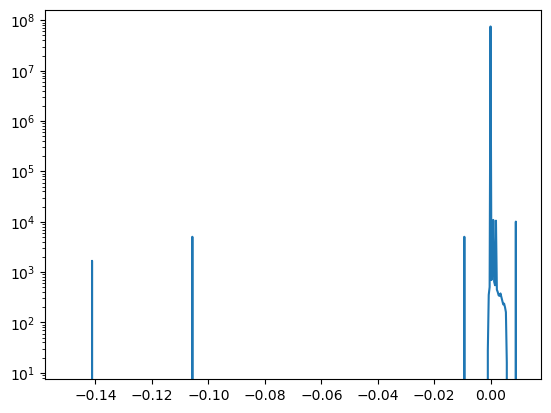

In [4]:
# Plot a test Histogram of 30-TBG's Wannier Hamiltonian Matrix Elements
test_hist, test_bin_edges = np.histogram(H.flatten(),range=(-0.15,0.01), bins=500)
test_bin_mids = (test_bin_edges[1:] + test_bin_edges[:-1]) / 2
plt.plot(test_bin_mids,test_hist)
plt.yscale('log')
plt.show()
